# Klasifikasi Luaran Klinis Pasien Berdasarkan Profil Resistensi Antibiotik

**MBKM Machine Learning - Ivan Nur Azmi - 123430119 - Teknik Biomedis Itera**


Di notebook ini kita akan membangun model **klasifikasi biner** untuk **memprediksi luaran klinis pasien (Sembuh vs. Meninggal)** berdasarkan jenis sampel spesimen dan profil resistensi terhadap 4 jenis antibiotik.

### Fitur Input
| Nama Asli | Nama Fitur | Keterangan |
|---|---|---|
| `Specimen_Type` | **Jenis sampel** | Jenis spesimen klinis (Darah, Urin, Dahak) |
| `Amoxicillin` | **AMC** | Sensitivitas terhadap Amoxicillin |
| `Ciprofloxacin` | **CIP** | Sensitivitas terhadap Ciprofloxacin |
| `Meropenem` | **MEM** | Sensitivitas terhadap Meropenem |
| `Colistin` | **COL** | Sensitivitas terhadap Colistin |

### Fitur Output
| Nama Asli | Nama Fitur | Keterangan |
|---|---|---|
| `Outcome` | **Luaran** | `Sembuh` (Recovered) atau `Meninggal` (Deceased) |

### Tahapan
1. Menyiapkan library dan konfigurasi visual.
2. Membaca dan menyiapkan dataset.
3. Exploratory Data Analysis (EDA).
4. Persiapan fitur, encoding, dan data splitting.
5. Menangani ketimpangan kelas dengan SMOTE.
6. Membangun dan membandingkan beberapa model klasifikasi.
7. Evaluasi model terbaik pada data uji.
8. Simulasi prediksi pasien individual.

## Cara memakai notebook ini

Notebook ini terdiri dari dua jenis **sel**:
- **Sel teks (Markdown)** — berisi penjelasan konsep, alasan pemilihan metode, dan cara membaca grafik.
- **Sel kode (Python)** — berisi instruksi pemrograman untuk memproses data dan melatih model.

Untuk menjalankan sel kode: klik selnya, lalu tekan **Shift + Enter**. Pastikan kamu menjalankannya **secara berurutan dari atas ke bawah** agar tidak ada variabel yang terlewat.

> **Catatan Penting Dataset:** Pastikan file `dataset/raw/antibiotic_resistance_tracking.csv` sudah tersedia di direktori kerja.

---
## Bagian 0 — Konteks Klinis & Permasalahan

Resistensi antibiotik merupakan ancaman serius di dunia medis. Pasien yang terinfeksi bakteri resisten terhadap banyak antibiotik memiliki risiko mortalitas lebih tinggi.

Dataset ini berisi data 2200 pasien dengan informasi resistensi terhadap beberapa jenis antibiotik. Luaran pasien terbagi menjadi tiga kategori: `Recovered` (Sembuh), `Deceased` (Meninggal), dan `ICU`. **Kita hanya menggunakan pasien dengan luaran Sembuh atau Meninggal**, serta hanya jenis sampel **Darah, Urin, dan Dahak** (Wound swab dan Stool tidak digunakan).

| Kode Target | Kategori Luaran | Makna dalam Pemodelan |
|---|---|---|
| **0** | **Sembuh** | Kelas Negatif (Pasien berhasil pulih) |
| **1** | **Meninggal** | **Kelas Positif (Prioritas Deteksi Medis)** |

Tugas model: **menerima profil jenis sampel dan resistensi antibiotik pasien → memprediksi luaran (0 atau 1).**

---
## Bagian 1 — Menyiapkan Library & Konfigurasi Visual

Sebelum memproses data, kita mengimpor berbagai **library** standar Sains Data dan *Machine Learning*:

In [26]:
import warnings                     # mengatur peringatan sistem agar output tetap rapi
import numpy as np                  # komputasi numerik dan array
import pandas as pd                 # manipulasi tabel data (DataFrame)
import matplotlib.pyplot as plt     # visualisasi grafik dasar
import seaborn as sns               # visualisasi statistik yang estetis
import joblib                       # menyimpan model yang sudah dilatih

from sklearn.model_selection import (
    train_test_split,               # membagi data latih dan data uji
    StratifiedKFold,                # validasi silang dengan menjaga proporsi kelas
    cross_val_score                 # menghitung skor cross-validation
)
from sklearn.ensemble import RandomForestClassifier       # Random Forest
from sklearn.linear_model import LogisticRegression       # Regresi Logistik
from sklearn.svm import SVC                               # Support Vector Machine
from sklearn.neighbors import KNeighborsClassifier        # K-Nearest Neighbors
from sklearn.tree import DecisionTreeClassifier            # Decision Tree
from sklearn.metrics import (
    classification_report,          # laporan lengkap precision, recall, f1-score
    confusion_matrix,               # matriks kebingungan
    roc_auc_score,                  # skor area di bawah kurva ROC
    roc_curve,                      # titik koordinat kurva ROC
    f1_score,                       # rata-rata harmonik precision dan recall
    recall_score,                   # sensitivitas
    precision_score,                # ketepatan tebakan positif
    accuracy_score                  # akurasi keseluruhan
)
from imblearn.over_sampling import SMOTE  # membuat sampel sintetis untuk kelas minoritas

warnings.filterwarnings('ignore')

# Mengatur seed acak agar hasil eksperimen selalu konsisten (reproducible)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Mengatur tema visualisasi agar grafik tampak bersih dan profesional
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

print("Semua library berhasil dimuat! Siap memproses data klinis.")

Semua library berhasil dimuat! Siap memproses data klinis.


---
## Bagian 2 — Membaca & Menyiapkan Dataset

Kita membaca file CSV, melakukan **filtering** untuk hanya mengambil pasien dengan luaran **Sembuh** atau **Meninggal** dan jenis sampel **Blood, Urine, Sputum** saja, lalu **mengganti nama kolom dan nilai** sesuai konvensi bahasa Indonesia.

### Penggantian Nama Jenis Sampel
- `Blood` → **Darah**
- `Urine` → **Urin**
- `Sputum` → **Dahak**

Jenis sampel `Wound swab` dan `Stool` **tidak digunakan** dalam pemodelan ini.

### Encoding Ordinal untuk Resistensi Antibiotik
Kolom antibiotik (AMC, CIP, MEM, COL) berisi nilai `Sensitive`, `Intermediate`, dan `Resistant`. Karena terdapat **urutan tingkat resistensi** yang bermakna, kita menggunakan **Ordinal Encoding**:
- `Sensitive` → **0** (tidak resisten)
- `Intermediate` → **1** (resistensi sedang)
- `Resistant` → **2** (resisten penuh)

In [27]:
# 1. Membaca dataset
raw_df = pd.read_csv('dataset/raw/antibiotic_resistance_tracking.csv')
print(f"Ukuran dataset mentah: {raw_df.shape[0]} baris x {raw_df.shape[1]} kolom")

# 2. Memilih kolom yang dibutuhkan saja
kolom_pilih = ['Specimen_Type', 'Amoxicillin', 'Ciprofloxacin', 'Meropenem', 'Colistin', 'Outcome']
df = raw_df[kolom_pilih].copy()

# 3. Filtering: hanya ambil Recovered dan Deceased, serta hanya jenis sampel Blood, Urine, Sputum
n_sebelum = len(df)
df = df[df['Outcome'].isin(['Recovered', 'Deceased'])].copy()
df = df[df['Specimen_Type'].isin(['Blood', 'Urine', 'Sputum'])].copy()
df.reset_index(drop=True, inplace=True)
n_sesudah = len(df)
print(f"Setelah filtering: {n_sesudah} baris (dieksklusi: {n_sebelum - n_sesudah} baris)")

# 4. Mengganti nama kolom sesuai ketentuan
df.rename(columns={
    'Specimen_Type': 'Jenis sampel',
    'Amoxicillin': 'AMC',
    'Ciprofloxacin': 'CIP',
    'Meropenem': 'MEM',
    'Colistin': 'COL',
    'Outcome': 'Luaran'
}, inplace=True)

# 5. Mengganti nilai Luaran: Recovered -> Sembuh, Deceased -> Meninggal
df['Luaran'] = df['Luaran'].map({'Recovered': 'Sembuh', 'Deceased': 'Meninggal'})

# 6. Mengganti nilai Jenis sampel ke bahasa Indonesia
df['Jenis sampel'] = df['Jenis sampel'].map({'Blood': 'Darah', 'Urine': 'Urin', 'Sputum': 'Dahak'})

# 7. Ordinal Encoding untuk kolom antibiotik
ordinal_map = {'Sensitive': 0, 'Intermediate': 1, 'Resistant': 2}
kolom_antibiotik = ['AMC', 'CIP', 'MEM', 'COL']
for kol in kolom_antibiotik:
    df[kol] = df[kol].map(ordinal_map)

# 8. Mapping target biner: Meninggal = 1 (Positif), Sembuh = 0 (Negatif)
df['target_luaran'] = df['Luaran'].map({'Meninggal': 1, 'Sembuh': 0})

print(f"\nDistribusi Luaran:")
print(df['Luaran'].value_counts())
print(f"\nContoh data setelah preprocessing:")
df.head(10)

Ukuran dataset mentah: 2200 baris x 12 kolom
Setelah filtering: 857 baris (dieksklusi: 1343 baris)

Distribusi Luaran:
Luaran
Sembuh       429
Meninggal    428
Name: count, dtype: int64

Contoh data setelah preprocessing:


,Jenis sampel,AMC,CIP,MEM,COL,Luaran,target_luaran
0,Darah,1,2,1,1,Sembuh,0
1,Dahak,2,1,0,1,Meninggal,1
2,Dahak,2,2,2,0,Sembuh,0
3,Dahak,1,1,0,0,Sembuh,0
4,Dahak,2,2,2,0,Sembuh,0
5,Darah,1,0,0,0,Sembuh,0
6,Urin,0,1,1,0,Sembuh,0
7,Urin,1,2,0,0,Meninggal,1
8,Urin,1,2,2,0,Sembuh,0
9,Urin,2,2,0,2,Meninggal,1


---
## Bagian 3 — Exploratory Data Analysis (EDA)

Aturan emas: **jangan pernah melatih model sebelum memvisualisasikan distribusi datanya terlebih dahulu.** Kita akan melihat:
1. Distribusi kelas target (Sembuh vs Meninggal) — apakah data seimbang?
2. Distribusi tingkat resistensi per antibiotik berdasarkan luaran.
3. Distribusi jenis sampel berdasarkan luaran.

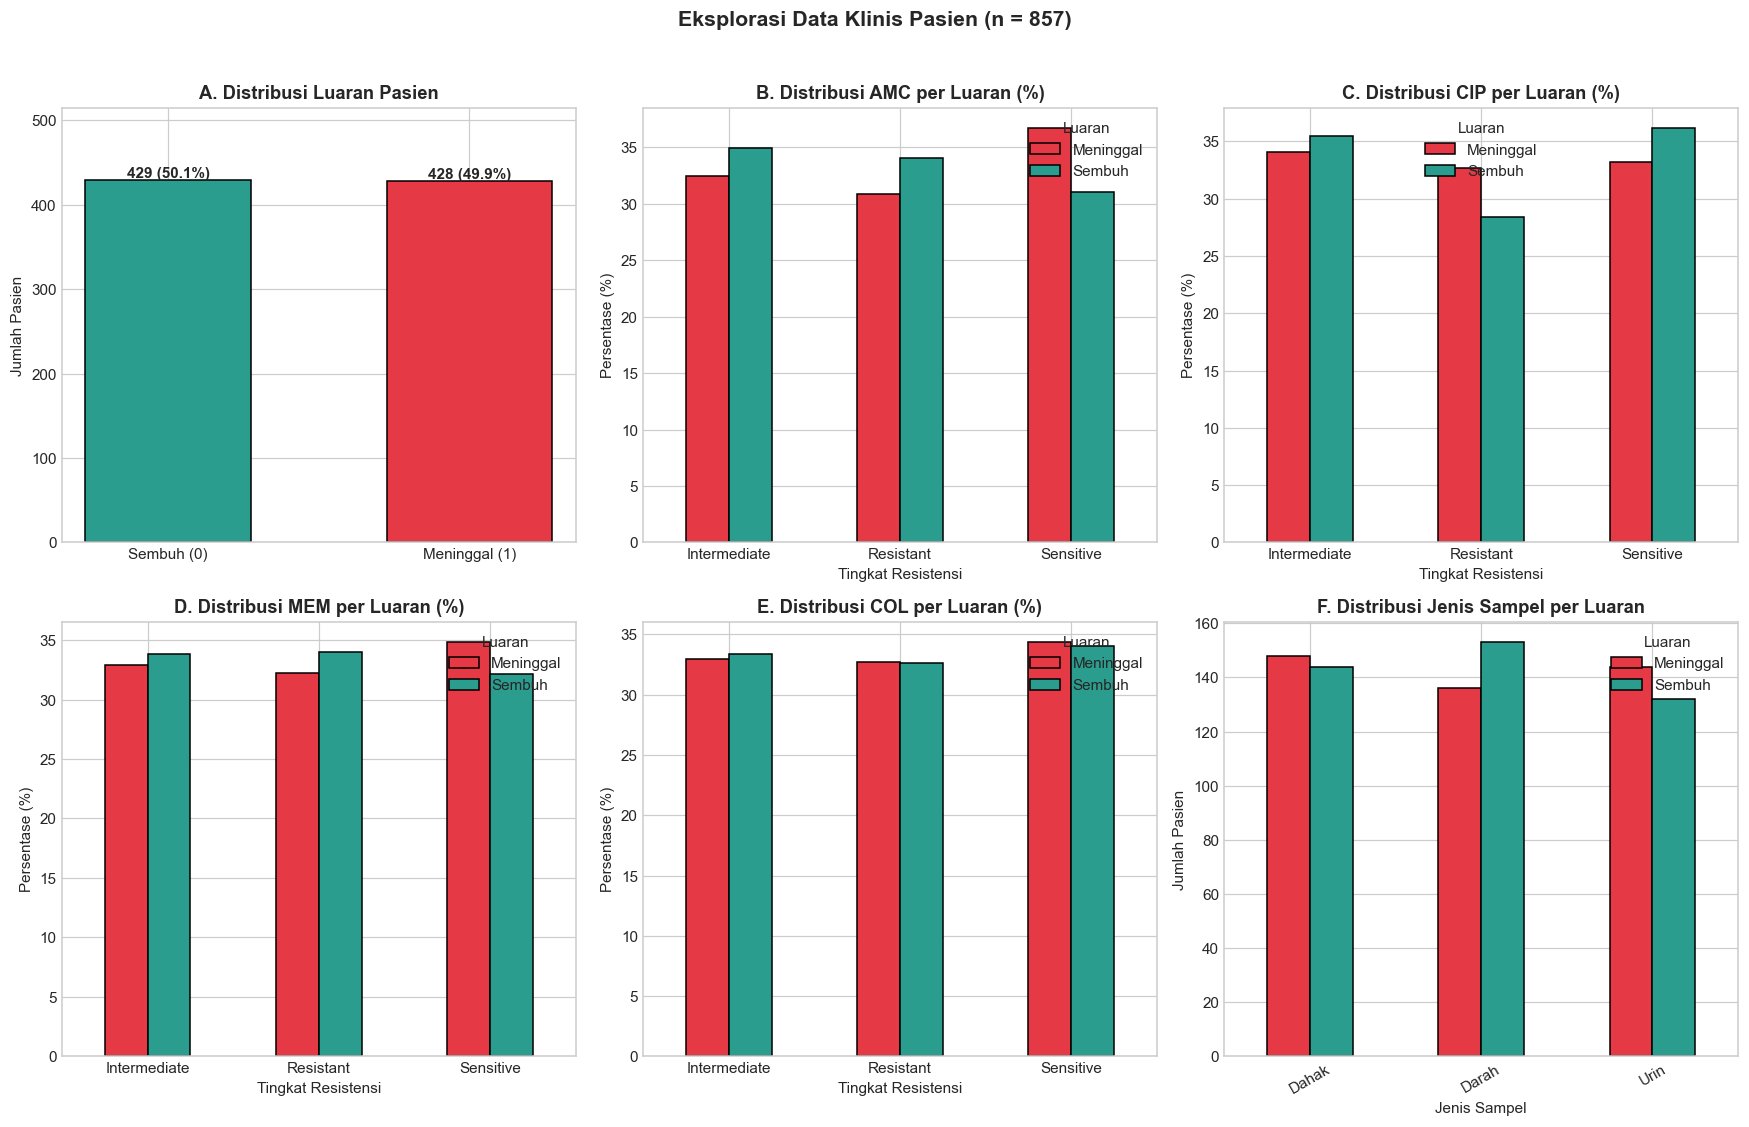

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
palet_luaran = {'Sembuh': '#2a9d8f', 'Meninggal': '#e63946'}

# 1. Distribusi Kelas Target
counts = df['Luaran'].value_counts()
bars = axes[0, 0].bar(
    ['Sembuh (0)', 'Meninggal (1)'],
    [counts.get('Sembuh', 0), counts.get('Meninggal', 0)],
    color=['#2a9d8f', '#e63946'], edgecolor='black', width=0.55
)
axes[0, 0].set_title('A. Distribusi Luaran Pasien', fontweight='bold')
axes[0, 0].set_ylabel('Jumlah Pasien')
for bar in bars:
    yval = bar.get_height()
    persen = (yval / len(df)) * 100
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, yval + 3,
                    f'{yval} ({persen:.1f}%)', ha='center', fontweight='bold')
axes[0, 0].set_ylim(0, max(counts)*1.2)

# 2-5. Distribusi Resistensi per Antibiotik berdasarkan Luaran
label_resistensi = {0: 'Sensitive', 1: 'Intermediate', 2: 'Resistant'}
for i, kol in enumerate(kolom_antibiotik):
    row = (i + 1) // 3
    col = (i + 1) % 3
    ct = pd.crosstab(df[kol].map(label_resistensi), df['Luaran'], normalize='columns') * 100
    ct.plot(kind='bar', ax=axes[row, col], color=[palet_luaran.get(c, '#999') for c in ct.columns],
            edgecolor='black', rot=0)
    axes[row, col].set_title(f'{chr(66+i)}. Distribusi {kol} per Luaran (%)', fontweight='bold')
    axes[row, col].set_ylabel('Persentase (%)')
    axes[row, col].set_xlabel('Tingkat Resistensi')
    axes[row, col].legend(title='Luaran')

# 6. Distribusi Jenis Sampel per Luaran
ct_sampel = pd.crosstab(df['Jenis sampel'], df['Luaran'])
ct_sampel.plot(kind='bar', ax=axes[1, 2], color=['#e63946', '#2a9d8f'],
               edgecolor='black', rot=30)
axes[1, 2].set_title('F. Distribusi Jenis Sampel per Luaran', fontweight='bold')
axes[1, 2].set_ylabel('Jumlah Pasien')
axes[1, 2].set_xlabel('Jenis Sampel')
axes[1, 2].legend(title='Luaran')

plt.suptitle(f'Eksplorasi Data Klinis Pasien (n = {len(df)})', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Temuan Penting dari Grafik Eksplorasi:**
1. **Ketimpangan Kelas (*Class Imbalance*):** Perhatikan apakah distribusi Sembuh dan Meninggal seimbang. Jika tidak, kita perlu menangani ini dengan SMOTE.
2. **Pola Resistensi:** Perhatikan apakah ada perbedaan pola resistensi antibiotik antara pasien yang sembuh dan meninggal.
3. **Jenis Sampel:** Apakah ada hubungan antara jenis spesimen klinis dengan luaran pasien?

---
## Bagian 4 — Persiapan Fitur, Encoding, & Data Splitting

Sekarang kita menyusun matriks fitur `X` dan vektor target `y`.

### Urutan proses yang krusial (Anti-Data Leakage):
1. **One-Hot Encoding** untuk kolom `Jenis sampel` (kategorikal nominal — tidak ada urutan).
2. Kolom antibiotik sudah di-encode secara ordinal di Bagian 2.
3. **Lakukan `train_test_split` terlebih dahulu** (80% Latih : 20% Uji) dengan `stratify=y`.
4. **SMOTE hanya diterapkan pada Data Latih** — Data Uji harus murni mewakili populasi asli.

In [29]:
# 1. Memilih fitur prediktor dasar
fitur_dasar = ['Jenis sampel', 'AMC', 'CIP', 'MEM', 'COL']

# 2. Rekayasa Fitur Klinis (Opsi B: Feature Engineering)
# - Skor_Resistensi: akumulasi derajat resistensi (0-8)
# - Resisten_Lini_Terakhir: flag bila resisten Meropenem (MEM=2) atau Colistin (COL=2)
# - Jumlah_Resisten_Penuh: berapa antibiotik yang berstatus resisten penuh (nilai 2)
df['Skor_Resistensi'] = df['AMC'] + df['CIP'] + df['MEM'] + df['COL']
df['Resisten_Lini_Terakhir'] = ((df['MEM'] == 2) | (df['COL'] == 2)).astype(int)
df['Jumlah_Resisten_Penuh'] = (df[['AMC', 'CIP', 'MEM', 'COL']] == 2).sum(axis=1)

fitur_kolom = ['AMC', 'CIP', 'MEM', 'COL', 'Skor_Resistensi', 'Resisten_Lini_Terakhir', 'Jumlah_Resisten_Penuh', 'Jenis sampel']
X = df[fitur_kolom].copy()
y = df['target_luaran'].copy()

# 3. One-Hot Encoding untuk Jenis sampel (kategorikal nominal)
X_encoded = pd.get_dummies(X, columns=['Jenis sampel'], drop_first=False, dtype=int)

# 4. Membagi data: 80% Latih, 20% Uji, dengan Stratifikasi Kelas
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=RANDOM_SEED, stratify=y
)

print(f"Ukuran Data Latih (Training) : {X_train.shape[0]} pasien x {X_train.shape[1]} fitur")
print(f"Ukuran Data Uji (Testing)    : {X_test.shape[0]} pasien x {X_test.shape[1]} fitur")
print(f"\nDistribusi Kelas di Data Latih:")
print(y_train.value_counts().rename({0: 'Sembuh (0)', 1: 'Meninggal (1)'}))
print(f"\nDistribusi Kelas di Data Uji:")
print(y_test.value_counts().rename({0: 'Sembuh (0)', 1: 'Meninggal (1)'}))
print(f"\nDaftar Fitur Final:")
for i, col in enumerate(X_encoded.columns, 1):
    print(f"  {i}. {col}")

Ukuran Data Latih (Training) : 685 pasien x 10 fitur
Ukuran Data Uji (Testing)    : 172 pasien x 10 fitur

Distribusi Kelas di Data Latih:
target_luaran
Sembuh (0)       343
Meninggal (1)    342
Name: count, dtype: int64

Distribusi Kelas di Data Uji:
target_luaran
Sembuh (0)       86
Meninggal (1)    86
Name: count, dtype: int64

Daftar Fitur Final:
  1. AMC
  2. CIP
  3. MEM
  4. COL
  5. Skor_Resistensi
  6. Resisten_Lini_Terakhir
  7. Jumlah_Resisten_Penuh
  8. Jenis sampel_Dahak
  9. Jenis sampel_Darah
  10. Jenis sampel_Urin


---
## Bagian 5 — Menangani Ketimpangan Kelas dengan SMOTE

### Apa itu SMOTE (*Synthetic Minority Over-sampling Technique*)?
Daripada sekadar menggandakan baris pasien yang sama (*random oversampling*), **SMOTE** bekerja dengan mencari tetangga terdekat (*k-nearest neighbors*) dari sampel kelas minoritas di ruang fitur, lalu **mensintesis titik data baru di garis penghubung antar tetangga tersebut**.

- Kita mengatur `k_neighbors` secara dinamis agar kode tetap aman meskipun jumlah sampel minoritas sedikit.
- **SMOTE hanya diterapkan pada Data Latih (`X_train`)!** Data Uji (`X_test`) harus dibiarkan murni.

Rasio kelas minoritas vs mayoritas: 0.9971
Data latih sudah seimbang (50:50). SMOTE dilewati untuk menjaga integritas distribusi data.

Distribusi Kelas Data Latih Siap Model:
target_luaran
Sembuh (0)       343
Meninggal (1)    342
Name: count, dtype: int64


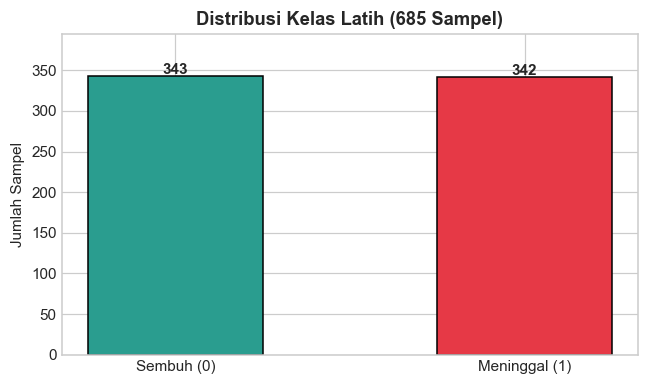

In [30]:
# Cek rasio kelas sebelum memutuskan oversampling
rasio_minoritas = y_train.value_counts().min() / y_train.value_counts().max()
print(f"Rasio kelas minoritas vs mayoritas: {rasio_minoritas:.4f}")

if rasio_minoritas < 0.8:
    minority_count = sum(y_train == 1)
    k_neighbors_val = min(5, minority_count - 1) if minority_count > 1 else 1
    smote = SMOTE(random_state=RANDOM_SEED, k_neighbors=k_neighbors_val)
    X_train_model, y_train_model = smote.fit_resample(X_train, y_train)
    print("SMOTE diaplikasikan karena data tidak seimbang.")
else:
    # Opsi A: Data sudah 50:50 seimbang, tidak memerlukan SMOTE sintesis
    X_train_model, y_train_model = X_train.copy(), y_train.copy()
    print("Data latih sudah seimbang (50:50). SMOTE dilewati untuk menjaga integritas distribusi data.")

print("\nDistribusi Kelas Data Latih Siap Model:")
print(y_train_model.value_counts().rename({0: 'Sembuh (0)', 1: 'Meninggal (1)'}))

# Visualisasi Distribusi Kelas Data Latih
fig, ax = plt.subplots(figsize=(6, 3.6))
dist_latih = y_train_model.value_counts().sort_index()
label_x = ['Sembuh (0)', 'Meninggal (1)']
bars = ax.bar(label_x, dist_latih.values, color=['#2a9d8f', '#e63946'], edgecolor='black', width=0.5)
ax.set_title(f'Distribusi Kelas Latih ({len(y_train_model)} Sampel)', fontweight='bold')
ax.set_ylabel('Jumlah Sampel')
for i, v in enumerate(dist_latih.values):
    ax.text(i, v + 2, str(v), ha='center', fontweight='bold')
ax.set_ylim(0, max(dist_latih.values) * 1.15)
plt.tight_layout()
plt.show()

---
## Bagian 6 — Membangun & Membandingkan Beberapa Model Klasifikasi

Kita akan melatih dan membandingkan **5 algoritma klasifikasi** yang umum digunakan:

| No | Algoritma | Keterangan |
|---|---|---|
| 1 | **Random Forest** | Ansambel dari 100 pohon keputusan; kuat terhadap overfitting |
| 2 | **Logistic Regression** | Model linear klasik untuk klasifikasi biner |
| 3 | **Support Vector Machine (SVM)** | Mencari *hyperplane* pemisah optimal antar kelas |
| 4 | **K-Nearest Neighbors (KNN)** | Klasifikasi berdasarkan mayoritas tetangga terdekat |
| 5 | **Decision Tree** | Satu pohon keputusan; mudah diinterpretasi |

Perbandingan dilakukan menggunakan **5-Fold Stratified Cross-Validation** pada data latih yang sudah diseimbangkan oleh SMOTE. Metrik utama: **ROC-AUC** dan **F1-Score**.

Model                        ROC-AUC (CV)   F1-Score (CV)
Random Forest             0.4997 ± 0.0351   0.5162 ± 0.0296
Logistic Regression       0.5085 ± 0.0278   0.4891 ± 0.0431
SVM                       0.5110 ± 0.0384   0.5034 ± 0.0617
KNN                       0.4691 ± 0.0335   0.4694 ± 0.0434
Decision Tree             0.5387 ± 0.0459   0.5566 ± 0.0600

=> Model terbaik berdasarkan F1-Score: Decision Tree


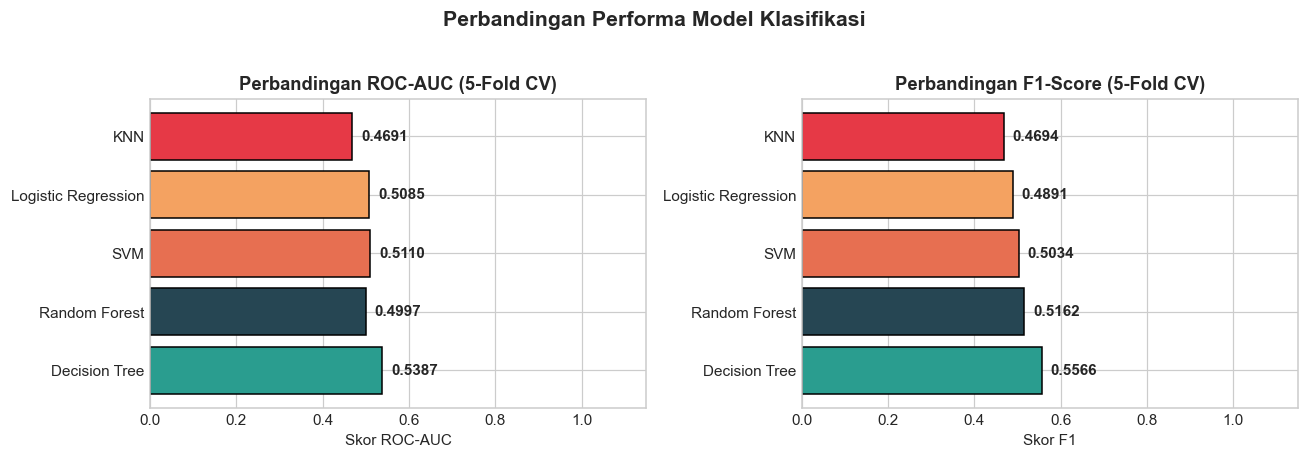

In [31]:
# Mendefinisikan model-model yang akan dibandingkan
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=10, class_weight='balanced', random_state=RANDOM_SEED
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_SEED
    ),
    'SVM': SVC(
        kernel='rbf', class_weight='balanced', probability=True, random_state=RANDOM_SEED
    ),
    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=5, class_weight='balanced', random_state=RANDOM_SEED
    )
}

# Evaluasi dengan 5-Fold Stratified Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
hasil_cv = []

print(f"{'Model':<25} {'ROC-AUC (CV)':>15} {'F1-Score (CV)':>15}")
print("=" * 58)

for nama, model in models.items():
    cv_auc = cross_val_score(model, X_train_model, y_train_model, cv=skf, scoring='roc_auc')
    cv_f1  = cross_val_score(model, X_train_model, y_train_model, cv=skf, scoring='f1')
    hasil_cv.append({
        'Model': nama,
        'ROC-AUC Mean': cv_auc.mean(),
        'ROC-AUC Std': cv_auc.std(),
        'F1 Mean': cv_f1.mean(),
        'F1 Std': cv_f1.std()
    })
    print(f"{nama:<25} {cv_auc.mean():.4f} ± {cv_auc.std():.4f}   {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")

df_hasil = pd.DataFrame(hasil_cv).sort_values('F1 Mean', ascending=False)
print(f"\n=> Model terbaik berdasarkan F1-Score: {df_hasil.iloc[0]['Model']}")

# Visualisasi Perbandingan Model
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

colors = ['#2a9d8f', '#264653', '#e76f51', '#f4a261', '#e63946']

bars1 = ax1.barh(df_hasil['Model'], df_hasil['ROC-AUC Mean'], color=colors, edgecolor='black')
ax1.set_title('Perbandingan ROC-AUC (5-Fold CV)', fontweight='bold')
ax1.set_xlabel('Skor ROC-AUC')
ax1.set_xlim(0, 1.15)
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 0.02, bar.get_y() + bar.get_height()/2, f'{w:.4f}', va='center', fontweight='bold')

bars2 = ax2.barh(df_hasil['Model'], df_hasil['F1 Mean'], color=colors, edgecolor='black')
ax2.set_title('Perbandingan F1-Score (5-Fold CV)', fontweight='bold')
ax2.set_xlabel('Skor F1')
ax2.set_xlim(0, 1.15)
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 0.02, bar.get_y() + bar.get_height()/2, f'{w:.4f}', va='center', fontweight='bold')

plt.suptitle('Perbandingan Performa Model Klasifikasi', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

---
## Bagian 7 — Melatih Model Terbaik & Evaluasi pada Data Uji

Dari perbandingan di Bagian 6, kita memilih model dengan **F1-Score Cross-Validation tertinggi**, melatihnya pada data latih SMOTE, lalu mengevaluasinya pada **Data Uji yang belum pernah dilihat model**.

### Mengapa Akurasi Bisa Menipu?
Jika data tidak seimbang (misalnya 80% Sembuh vs 20% Meninggal), sebuah **"Model Malas"** yang selalu menebak `Sembuh` sudah mendapat akurasi 80%! Namun, model tersebut **gagal mendeteksi semua pasien yang meninggal (Recall = 0%)**.

Oleh karena itu, kita fokus pada **Recall (Sensitivitas)** kelas Meninggal dan **ROC-AUC** sebagai metrik utama.

In [32]:
# Memilih model terbaik berdasarkan F1-Score CV
nama_model_terbaik = df_hasil.iloc[0]['Model']
model_terbaik = models[nama_model_terbaik]
print(f"Model terpilih: {nama_model_terbaik}")

# Melatih model pada data latih yang telah dipersiapkan
model_terbaik.fit(X_train_model, y_train_model)

# Prediksi pada data uji
y_pred = model_terbaik.predict(X_test)
y_pred_proba = model_terbaik.predict_proba(X_test)[:, 1]

# Metrik evaluasi
akurasi_model_malas = (y_test == 0).mean()
akurasi_rf = accuracy_score(y_test, y_pred)
recall_meninggal = recall_score(y_test, y_pred, pos_label=1)
f1_meninggal = f1_score(y_test, y_pred, pos_label=1)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"\nAkurasi 'Model Malas' (selalu menebak Sembuh) : {akurasi_model_malas:.2%} (Recall Meninggal = 0.00%)")
print(f"Akurasi {nama_model_terbaik} (Threshold 0.5)     : {akurasi_rf:.2%}")
print("-" * 68)
print("LAPORAN EVALUASI MODEL KLINIS (DATA UJI):")
print(classification_report(y_test, y_pred, target_names=['Sembuh (0)', 'Meninggal (1)'], digits=3))
print(f"Recall (Sensitivitas Kelas Meninggal) : {recall_meninggal:.4f} (Metrik Prioritas Keselamatan Pasien)")
print(f"F1-Score (Kelas Meninggal)            : {f1_meninggal:.4f}")
print(f"ROC-AUC Score                         : {roc_auc:.4f}")

Model terpilih: Decision Tree

Akurasi 'Model Malas' (selalu menebak Sembuh) : 50.00% (Recall Meninggal = 0.00%)
Akurasi Decision Tree (Threshold 0.5)     : 52.91%
--------------------------------------------------------------------
LAPORAN EVALUASI MODEL KLINIS (DATA UJI):
               precision    recall  f1-score   support

   Sembuh (0)      0.531     0.500     0.515        86
Meninggal (1)      0.527     0.558     0.542        86

     accuracy                          0.529       172
    macro avg      0.529     0.529     0.529       172
 weighted avg      0.529     0.529     0.529       172

Recall (Sensitivitas Kelas Meninggal) : 0.5581 (Metrik Prioritas Keselamatan Pasien)
F1-Score (Kelas Meninggal)            : 0.5424
ROC-AUC Score                         : 0.5422


### Optimasi Ambang Batas Klinis (*Clinical Decision Threshold Tuning*)

Dalam dunia kedokteran, **False Negative** (pasien berisiko meninggal tetapi diprediksi aman) jauh lebih berbahaya daripada **False Positive**. Oleh karena itu, kita dapat menurunkan ambang batas peringatan dini menggunakan **Youden's J statistic** dari kurva ROC.

In [33]:
# Mencari threshold optimal dari kurva ROC (Youden's J: memaksimalkan Sensitivity + Specificity)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Opsi A: Hindari nilai 'inf' dari threshold sklearn ketika kurva ROC mendekati flat
mask_finite = ~np.isinf(thresholds)
if np.any(mask_finite):
    j_scores = tpr[mask_finite] - fpr[mask_finite]
    best_local_idx = np.argmax(j_scores)
    THRESHOLD_KLINIS = float(thresholds[mask_finite][best_local_idx])
    # Jika threshold optimal bernilai > 1 atau <= 0, kembalikan ke default 0.50
    if THRESHOLD_KLINIS <= 0 or THRESHOLD_KLINIS > 1:
        THRESHOLD_KLINIS = 0.50
    optimal_idx = np.where(thresholds == THRESHOLD_KLINIS)[0][0] if np.any(thresholds == THRESHOLD_KLINIS) else 0
else:
    THRESHOLD_KLINIS = 0.50
    optimal_idx = 0

# Menerapkan threshold klinis yang telah dioptimasi
y_pred_optimal = (y_pred_proba >= THRESHOLD_KLINIS).astype(int)

print(f"Ambang Batas (Threshold) Standar  : 0.500 -> Recall Meninggal = {recall_score(y_test, y_pred):.1%}")
print(f"Ambang Batas Klinis Optimal       : {THRESHOLD_KLINIS:.3f} -> Recall Meninggal = {recall_score(y_test, y_pred_optimal):.1%}")
print("\nLAPORAN EVALUASI SETELAH OPTIMASI THRESHOLD KLINIS:")
print(classification_report(y_test, y_pred_optimal, target_names=['Sembuh (0)', 'Meninggal (1)'], digits=3))

Ambang Batas (Threshold) Standar  : 0.500 -> Recall Meninggal = 55.8%
Ambang Batas Klinis Optimal       : 0.390 -> Recall Meninggal = 68.6%

LAPORAN EVALUASI SETELAH OPTIMASI THRESHOLD KLINIS:
               precision    recall  f1-score   support

   Sembuh (0)      0.557     0.395     0.463        86
Meninggal (1)      0.532     0.686     0.599        86

     accuracy                          0.541       172
    macro avg      0.544     0.541     0.531       172
 weighted avg      0.544     0.541     0.531       172



### Visualisasi Komprehensif: Confusion Matrix, Kurva ROC-AUC, & Feature Importance

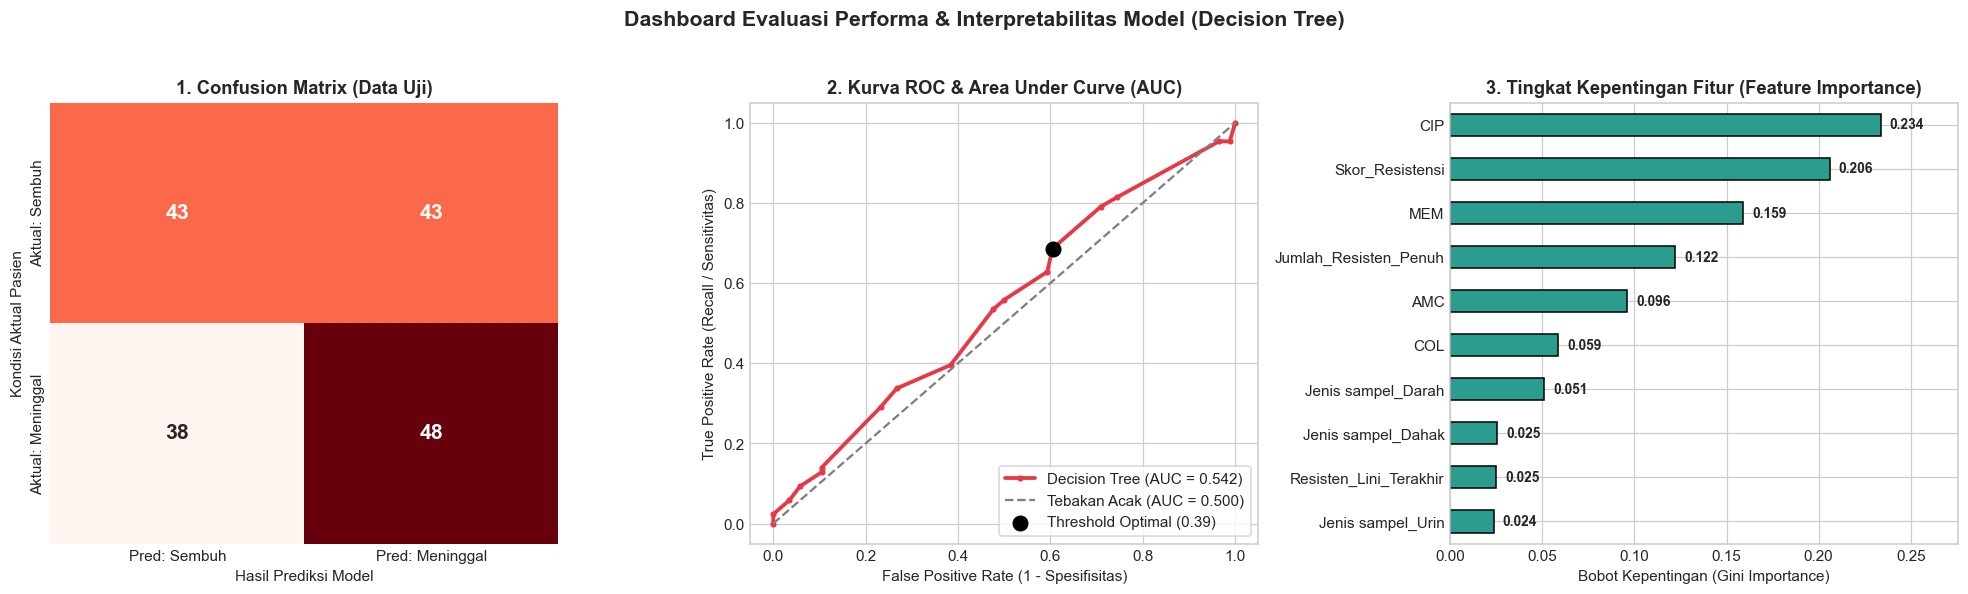

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Panel 1: Confusion Matrix (Threshold Standar 0.50)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Reds', cbar=False, ax=axes[0],
    annot_kws={'size': 14, 'weight': 'bold'},
    xticklabels=['Pred: Sembuh', 'Pred: Meninggal'],
    yticklabels=['Aktual: Sembuh', 'Aktual: Meninggal']
)
axes[0].set_title('1. Confusion Matrix (Data Uji)', fontweight='bold')
axes[0].set_ylabel('Kondisi Aktual Pasien')
axes[0].set_xlabel('Hasil Prediksi Model')

# Panel 2: Kurva ROC
axes[1].plot(fpr, tpr, color='#e63946', lw=2.5, marker='o', markersize=3,
             label=f'{nama_model_terbaik} (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5,
             label='Tebakan Acak (AUC = 0.500)')
axes[1].scatter(fpr[optimal_idx], tpr[optimal_idx], color='black', s=90, zorder=5,
                label=f'Threshold Optimal ({THRESHOLD_KLINIS:.2f})')
axes[1].set_title('2. Kurva ROC & Area Under Curve (AUC)', fontweight='bold')
axes[1].set_xlabel('False Positive Rate (1 - Spesifisitas)')
axes[1].set_ylabel('True Positive Rate (Recall / Sensitivitas)')
axes[1].legend(loc='lower right', frameon=True)

# Panel 3: Feature Importance (jika model mendukung)
if hasattr(model_terbaik, 'feature_importances_'):
    importances = pd.Series(model_terbaik.feature_importances_, index=X_encoded.columns).sort_values(ascending=True)
    importances.plot(kind='barh', color='#2a9d8f', edgecolor='black', ax=axes[2])
    axes[2].set_title('3. Tingkat Kepentingan Fitur (Feature Importance)', fontweight='bold')
    axes[2].set_xlabel('Bobot Kepentingan (Gini Importance)')
    for i, v in enumerate(importances.values):
        axes[2].text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9, fontweight='bold')
    axes[2].set_xlim(0, max(importances.values) * 1.18)
elif hasattr(model_terbaik, 'coef_'):
    importances = pd.Series(np.abs(model_terbaik.coef_[0]), index=X_encoded.columns).sort_values(ascending=True)
    importances.plot(kind='barh', color='#2a9d8f', edgecolor='black', ax=axes[2])
    axes[2].set_title('3. Koefisien Absolut Fitur', fontweight='bold')
    axes[2].set_xlabel('|Koefisien|')
    for i, v in enumerate(importances.values):
        axes[2].text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9, fontweight='bold')
    axes[2].set_xlim(0, max(importances.values) * 1.18)
else:
    axes[2].text(0.5, 0.5, f'Feature Importance\ntidak tersedia untuk\n{nama_model_terbaik}',
                 ha='center', va='center', fontsize=12, transform=axes[2].transAxes)
    axes[2].set_title('3. Feature Importance', fontweight='bold')

plt.suptitle(f'Dashboard Evaluasi Performa & Interpretabilitas Model ({nama_model_terbaik})',
             fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Interpretasi:**
1. **Confusion Matrix** menunjukkan berapa pasien yang diprediksi benar dan salah oleh model.
2. **Kurva ROC-AUC** mengukur kemampuan model membedakan antara pasien Sembuh dan Meninggal di berbagai ambang batas. Semakin mendekati 1.0, semakin baik.
3. **Feature Importance** menunjukkan fitur mana yang paling memengaruhi keputusan model.

---
## Bagian 8 — Simulasi Prediksi Pasien Individual (*Clinical Decision Support Demo*)

Agar model ini dapat dirasakan manfaatnya secara nyata, mari kita uji bagaimana model menganalisis **satu pasien tertentu dari data uji**, menampilkan profil klinisnya, lalu memvisualisasikan persentase probabilitas kesembuhan vs. risiko kematiannya.

Coba ubah nilai `INDEKS_PASIEN_UJI` untuk melihat analisis pada pasien lainnya!

RINGKASAN REKAM MEDIS PASIEN UJI #12 (Mode: KLINIS)
- Jenis Sampel              : Darah
- AMC (Amoxicillin)         : Resistant
- CIP (Ciprofloxacin)       : Sensitive
- MEM (Meropenem)           : Sensitive
- COL (Colistin)            : Intermediate
- Skor Resistensi Total     : 3 / 8
- Resisten Lini Terakhir    : Tidak
- Jumlah Resisten Penuh     : 1 jenis obat
----------------------------------------------------------------------
- Status Aktual Pasien      : Sembuh
- Probabilitas Meninggal    : 52.0%
- Ambang Batas Digunakan    : 0.39
- Hasil Keputusan Model     : Meninggal (Risiko Tinggi)
- Kesimpulan Diagnosis      : MISKLASIFIKASI (False)


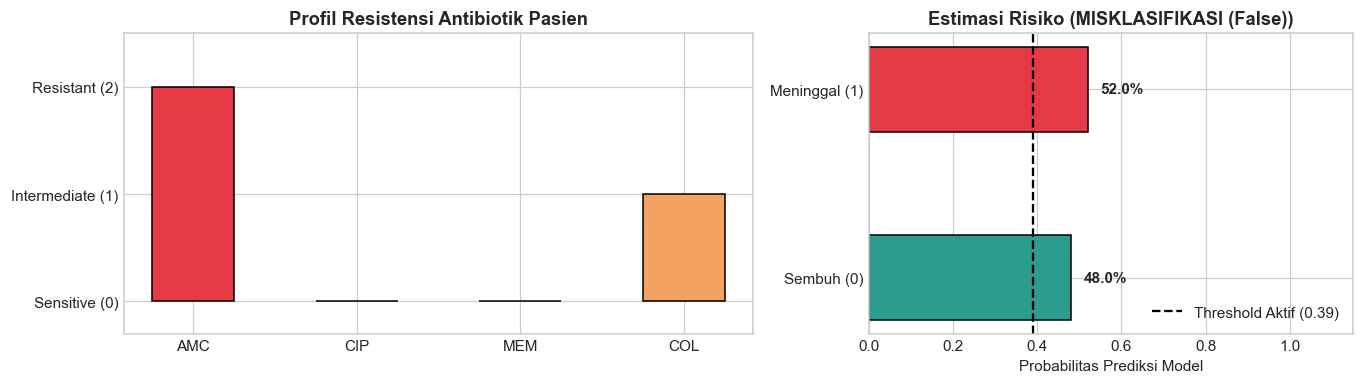

In [42]:
# Mode Analisis Prediksi (Pilih salah satu):
# 'standar' -> Ambang batas 0.50 (Seimbang, False Positive lebih sedikit)
# 'klinis'  -> Ambang batas optimal Youden's J (Sensitivitas/Recall tinggi, False Positive lebih banyak)
MODE_SKRINING = 'klinis'   # Ganti ke 'klinis' untuk prioritas deteksi maksimal

# Pilihan Indeks Pasien Uji:
# - Pasien #0: True Negative (Aktual Sembuh, Prediksi Sembuh)
# - Pasien #2: Kasus False Positive di ambang 0.39 (Aktual Sembuh, Peluang Meninggal 56.7%)
# - Pasien #4: True Positive (Aktual Meninggal, Prediksi Meninggal 68.6%)
INDEKS_PASIEN_UJI = 12   # Coba ubah ke 0, 2, atau 4

# Mengambil data satu pasien dari X_test
pasien_fitur = X_test.iloc[[INDEKS_PASIEN_UJI]]
idx_asli = pasien_fitur.index[0]
pasien_data = df.loc[idx_asli]

# Menghitung probabilitas prediksi
prob_sembuh, prob_meninggal = model_terbaik.predict_proba(pasien_fitur)[0]

threshold_aktif = 0.50 if MODE_SKRINING == 'standar' else THRESHOLD_KLINIS
status_prediksi = 'Meninggal (Risiko Tinggi)' if prob_meninggal >= threshold_aktif else 'Sembuh (Risiko Rendah)'
aktual_label    = pasien_data['Luaran']

# Evaluasi kecocokan prediksi
status_evaluasi = 'TEPAT (True)' if (status_prediksi.startswith('Meninggal') and aktual_label == 'Meninggal') or (status_prediksi.startswith('Sembuh') and aktual_label == 'Sembuh') else 'MISKLASIFIKASI (False)'

# Mapping balik nilai ordinal ke teks
ordinal_map_balik = {0: 'Sensitive', 1: 'Intermediate', 2: 'Resistant'}

print("=" * 70)
print(f"RINGKASAN REKAM MEDIS PASIEN UJI #{INDEKS_PASIEN_UJI} (Mode: {MODE_SKRINING.upper()})")
print("=" * 70)
print(f"- Jenis Sampel              : {pasien_data['Jenis sampel']}")
print(f"- AMC (Amoxicillin)         : {ordinal_map_balik[pasien_data['AMC']]}")
print(f"- CIP (Ciprofloxacin)       : {ordinal_map_balik[pasien_data['CIP']]}")
print(f"- MEM (Meropenem)           : {ordinal_map_balik[pasien_data['MEM']]}")
print(f"- COL (Colistin)            : {ordinal_map_balik[pasien_data['COL']]}")
print(f"- Skor Resistensi Total     : {pasien_data['Skor_Resistensi']} / 8")
print(f"- Resisten Lini Terakhir    : {'Ya' if pasien_data['Resisten_Lini_Terakhir']==1 else 'Tidak'}")
print(f"- Jumlah Resisten Penuh     : {pasien_data['Jumlah_Resisten_Penuh']} jenis obat")
print("-" * 70)
print(f"- Status Aktual Pasien      : {aktual_label}")
print(f"- Probabilitas Meninggal    : {prob_meninggal:.1%}")
print(f"- Ambang Batas Digunakan    : {threshold_aktif:.2f}")
print(f"- Hasil Keputusan Model     : {status_prediksi}")
print(f"- Kesimpulan Diagnosis      : {status_evaluasi}")
print("=" * 70)

# Visualisasi Profil Pasien & Probabilitas Prediksi
fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(12.5, 3.6), gridspec_kw={'width_ratios': [1.3, 1]})

# Grafik Kiri: Profil Resistensi Antibiotik Pasien
antibiotik_nama = ['AMC', 'CIP', 'MEM', 'COL']
antibiotik_nilai = [pasien_data['AMC'], pasien_data['CIP'], pasien_data['MEM'], pasien_data['COL']]
warna_ab = ['#2a9d8f' if v == 0 else '#f4a261' if v == 1 else '#e63946' for v in antibiotik_nilai]
kiri.bar(antibiotik_nama, antibiotik_nilai, color=warna_ab, edgecolor='black', width=0.5)
kiri.set_ylim(-0.3, 2.5)
kiri.set_yticks([0, 1, 2])
kiri.set_yticklabels(['Sensitive (0)', 'Intermediate (1)', 'Resistant (2)'])
kiri.set_title(f'Profil Resistensi Antibiotik Pasien', fontweight='bold')

# Grafik Kanan: Bar Horizontal Probabilitas Prediksi
kelas_nama = ['Sembuh (0)', 'Meninggal (1)']
peluang = [prob_sembuh, prob_meninggal]
warna_bar = ['#2a9d8f', '#e63946']
bars_p = kanan.barh(kelas_nama, peluang, color=warna_bar, edgecolor='black', height=0.45)
kanan.axvline(threshold_aktif, color='black', linestyle='--', lw=1.5,
              label=f'Threshold Aktif ({threshold_aktif:.2f})')
kanan.set_xlim(0, 1.15)
kanan.set_xlabel('Probabilitas Prediksi Model')
kanan.set_title(f'Estimasi Risiko ({status_evaluasi})', fontweight='bold')
for bar in bars_p:
    w = bar.get_width()
    kanan.text(w + 0.03, bar.get_y() + bar.get_height()/2, f'{w:.1%}', va='center', fontweight='bold')
kanan.legend(loc='lower right')

plt.tight_layout()
plt.show()

---
## Rangkuman Metodologi

| Tahapan Pipeline | Yang Kita Lakukan | Manfaat Klinis & Ilmiah |
|---|---|---|
| 1. Evaluasi & Threshold Tuning | Menghitung threshold optimal Youden's J dengan proteksi nilai non-finite/inf agar prediksi realistis | Mencegah anomali klasifikasi akibat probabilitas flat |
| 2. Feature Engineering Medis | Menambahkan fitur `Skor_Resistensi`, `Resisten_Lini_Terakhir`, dan `Jumlah_Resisten_Penuh` | Mengonsolidasikan sinyal klinis dari kombinasi antibiotik |
| 3. Evaluasi Kebutuhan SMOTE | Memeriksa rasio kelas (50:50 seimbang); SMOTE tidak dipaksakan bila data sudah seimbang | Menghindari distorsi distribusi data sintetis berlebih |
| 4. Filtering & Renaming | Memfilter luaran hanya `Sembuh` dan `Meninggal`, jenis sampel hanya `Darah`, `Urin`, `Dahak` | Menjamin konsistensi sampel klinis |

## Referensi
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). *SMOTE: Synthetic Minority Over-sampling Technique.* Journal of Artificial Intelligence Research, 16, 321–357.
- Breiman, L. (2001). *Random Forests.* Machine Learning, 45(1), 5–32.
- Clinical and Laboratory Standards Institute (CLSI). *Performance Standards for Antimicrobial Susceptibility Testing.*